# Deutsch algorithm implementation using Qiskit library

## Imports

In [8]:
from qiskit import QuantumCircuit, transpile
from qiskit_aer import AerSimulator

## Oracle construction

In [9]:
def deutsch_qiskit_oracle(function):

    oracle = QuantumCircuit(2, name="Uf")

    if function == "constant_zero":
        pass

    elif function == "constant_one":
        oracle.x(1)

    elif function == "identity":
        oracle.cx(0, 1)

    elif function == "negation":
        oracle.x(1)
        oracle.cx(0, 1)

    else:
        raise ValueError("Unknown function")

    return oracle.to_gate()

## Circuit construction

In [10]:
def deutsch_circuit(function, measure=True):

    qc = QuantumCircuit(2, 1 if measure else 0)

    # Initialize |01>
    qc.x(1)

    # Hadamard on both qubits
    qc.h(0)
    qc.h(1)

    qc.barrier()

    # Oracle
    oracle = deutsch_qiskit_oracle(function)
    qc.append(oracle, [0, 1])

    qc.barrier()

    # Final Hadamard on input qubit
    qc.h(0)

    qc.barrier()

    if measure:
        qc.measure(0, 0)

    return qc

## Visualize circuit

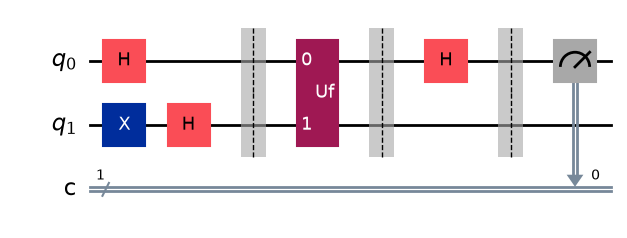

In [11]:
qc = deutsch_circuit("identity")

qc.draw("mpl")

## Simulate

In [12]:
def run_deutsch(function, shots=1024):

    qc = deutsch_circuit(function)

    simulator = AerSimulator()

    compiled = transpile(qc, simulator)

    result = simulator.run(
        compiled,
        shots=shots
    ).result()

    counts = result.get_counts()

    if set(counts.keys()) == {"0"}:
        classification = "CONSTANT"

    elif set(counts.keys()) == {"1"}:
        classification = "BALANCED"

    else:
        classification = "INCONCLUSIVE"

    print(f"Function: {function}")
    print("Counts:", counts)
    print("Classification:", classification)

    return counts

## Test all functions

In [13]:
functions = [
    "constant_zero",
    "constant_one",
    "identity",
    "negation"
]

for function in functions:

    print("\n--------------------------")

    run_deutsch(function)


--------------------------
Function: constant_zero
Counts: {'0': 1024}
Classification: CONSTANT

--------------------------
Function: constant_one
Counts: {'0': 1024}
Classification: CONSTANT

--------------------------
Function: identity
Counts: {'1': 1024}
Classification: BALANCED

--------------------------
Function: negation
Counts: {'1': 1024}
Classification: BALANCED


## Compare circuits

In [14]:
for function in functions:

    print(f"\nOracle: {function}")

    circuit = deutsch_circuit(function)

    print(circuit.draw("text"))


Oracle: constant_zero
     ┌───┐      ░ ┌─────┐ ░ ┌───┐ ░ ┌─┐
q_0: ┤ H ├──────░─┤0    ├─░─┤ H ├─░─┤M├
     ├───┤┌───┐ ░ │  Uf │ ░ └───┘ ░ └╥┘
q_1: ┤ X ├┤ H ├─░─┤1    ├─░───────░──╫─
     └───┘└───┘ ░ └─────┘ ░       ░  ║ 
c: 1/════════════════════════════════╩═
                                     0 

Oracle: constant_one
     ┌───┐      ░ ┌─────┐ ░ ┌───┐ ░ ┌─┐
q_0: ┤ H ├──────░─┤0    ├─░─┤ H ├─░─┤M├
     ├───┤┌───┐ ░ │  Uf │ ░ └───┘ ░ └╥┘
q_1: ┤ X ├┤ H ├─░─┤1    ├─░───────░──╫─
     └───┘└───┘ ░ └─────┘ ░       ░  ║ 
c: 1/════════════════════════════════╩═
                                     0 

Oracle: identity
     ┌───┐      ░ ┌─────┐ ░ ┌───┐ ░ ┌─┐
q_0: ┤ H ├──────░─┤0    ├─░─┤ H ├─░─┤M├
     ├───┤┌───┐ ░ │  Uf │ ░ └───┘ ░ └╥┘
q_1: ┤ X ├┤ H ├─░─┤1    ├─░───────░──╫─
     └───┘└───┘ ░ └─────┘ ░       ░  ║ 
c: 1/════════════════════════════════╩═
                                     0 

Oracle: negation
     ┌───┐      ░ ┌─────┐ ░ ┌───┐ ░ ┌─┐
q_0: ┤ H ├──────░─┤0    ├─░─┤ H ├─░─┤M├